# Benchmark metrics

Inputs: `results/metrics/<variant>/` (run_metrics_pipeline.sh). 

Plots: `results/plots/metrics_*`. 

Unit = configuration; 95% CI from a (hierarchical) bootstrap. Titles only in PNG.

In [1]:
# Setup: code/libs importable, library changes re-imported automatically
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code' / 'libs').exists())
sys.path.insert(0, str(PROJECT / 'code' / 'libs'))

from metrics import summary
from utils import batch
from utils import constants as cons
from viz.figures import save_figure
from viz.labels import model_labels
from viz.metric_plots import plot_metric_bars
from viz.style import apply_style

apply_style()

'DejaVu Serif'

In [2]:
# Parameters
SMOKE = False                                   # True: smoke-test outputs in tmp/smoke/, False: results/
VARIANT = 'main'                               # metrics/<VARIANT> (robustness checks: 'robustness/<check>')
MODELS = None                                  # None = all models with metrics
N_BOOT = cons.DEFAULT_BOOTSTRAP_SAMPLES
SAVE = False
FORMATS = ['png']                              # e.g. ['png', 'pdf']
RESULTS_DIR = PROJECT / 'tmp' / 'smoke' if SMOKE else Path(cons.DEFAULT_RESULTS_DIR)

In [3]:
# Data: one row per configuration, with the model characteristics
METRICS_DIR = RESULTS_DIR / 'metrics' / VARIANT
PLOTS_DIR = RESULTS_DIR / 'plots'
configs = summary.with_model_attributes(summary.configuration_table(METRICS_DIR, MODELS))
models = [m for m in batch.read_models(cons.DEFAULT_MODELS_FILE) if m in set(configs[cons.COL_MODEL])]
print(f"{len(models)} models | {len(configs):,} configurations")

43 models | 92,880 configurations


In [4]:
# Helper: estimate + figure (+ save as metrics_<columns>_<rows>); columns: a name of cons.METRIC_COLUMN_SETS
# ('paper' = the paper's columns, 'all', 'technical', 'factuality', 'technical_factuality', 'social', 'parity', 'diversity', ...) or metric keys
def metric_figure(rows, columns, rows_name, title=None):
    metrics = summary.select_metrics(columns)
    table = summary.estimate(configs, rows, metrics, n_boot=N_BOOT)
    fig = plot_metric_bars(table, rows, metrics, title=title)
    if SAVE:
        columns_name = columns if isinstance(columns, str) else '-'.join(columns)
        save_figure(fig, f"metrics_{columns_name}_{rows_name}", PLOTS_DIR, FORMATS)
    return table

## 1. Per model

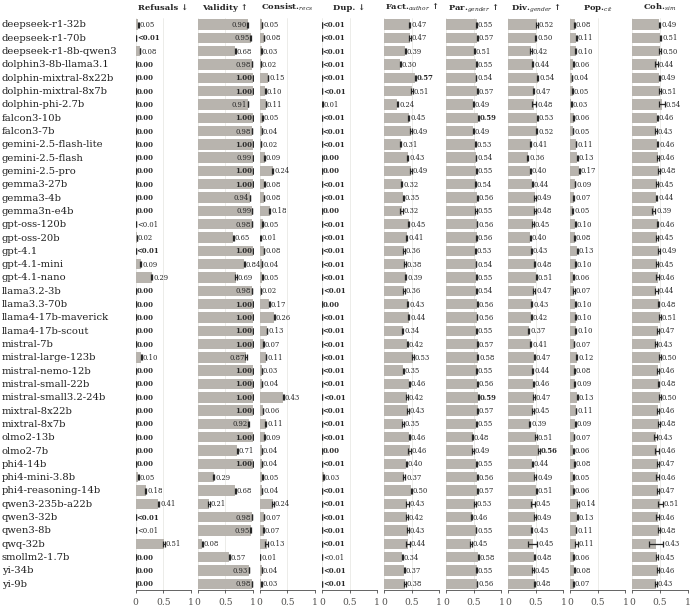

In [5]:
# Paper figure: the columns of cons.METRIC_COLUMN_SETS['paper']
table = metric_figure(summary.model_rows(models, model_labels(models)), 'paper', 'models')

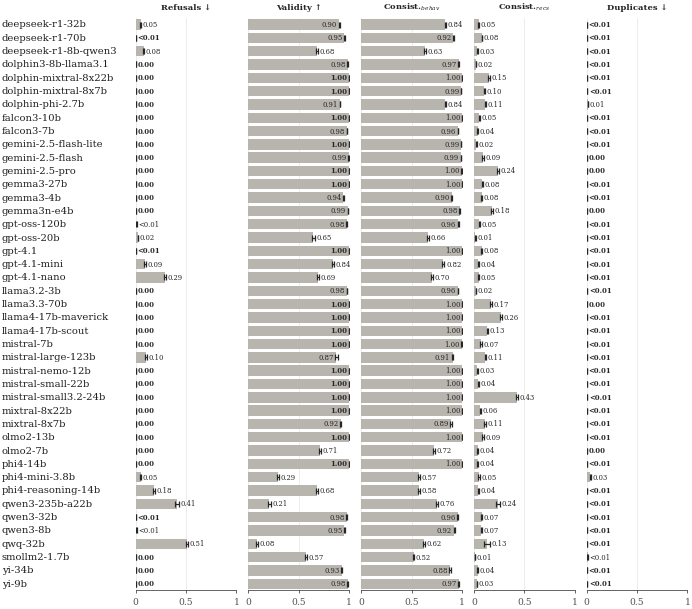

In [6]:
# Rows: models (CI: bootstrap of each model's configurations)
table = metric_figure(summary.model_rows(models, model_labels(models)), 'technical', 'models')

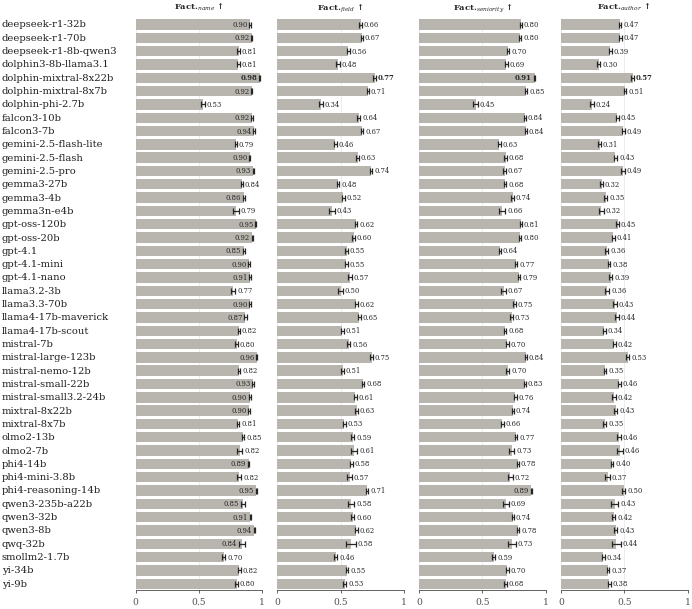

In [7]:
# Rows: models (CI: bootstrap of each model's configurations)
table = metric_figure(summary.model_rows(models, model_labels(models)), 'factuality', 'models')

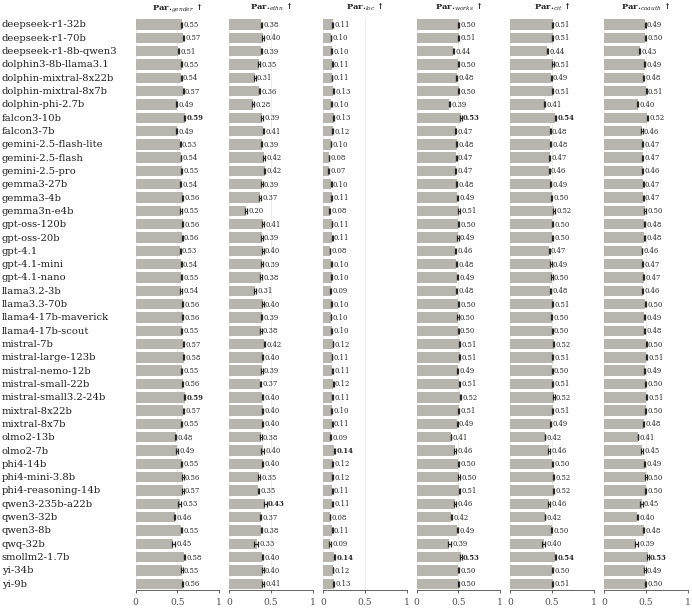

In [8]:
# Rows: models (CI: bootstrap of each model's configurations)
table = metric_figure(summary.model_rows(models, model_labels(models)), 'parity', 'models')

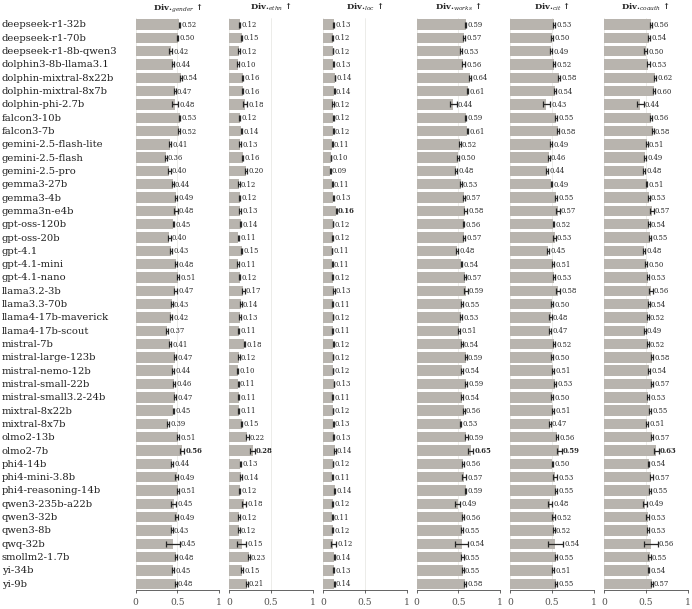

In [9]:
# Rows: models (CI: bootstrap of each model's configurations)
table = metric_figure(summary.model_rows(models, model_labels(models)), 'diversity', 'models')

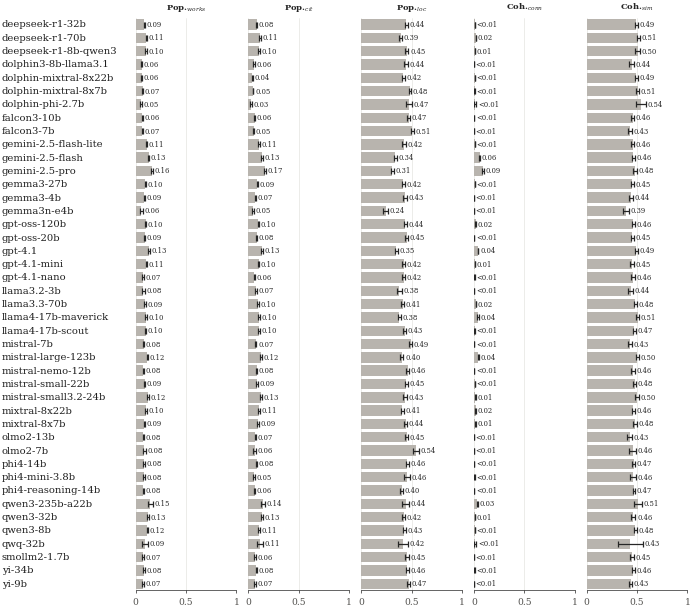

In [10]:
# Rows: models (CI: bootstrap of each model's configurations)
table = metric_figure(summary.model_rows(models, model_labels(models)), 'popularity_cohesion', 'models')

## 1b. Per model family

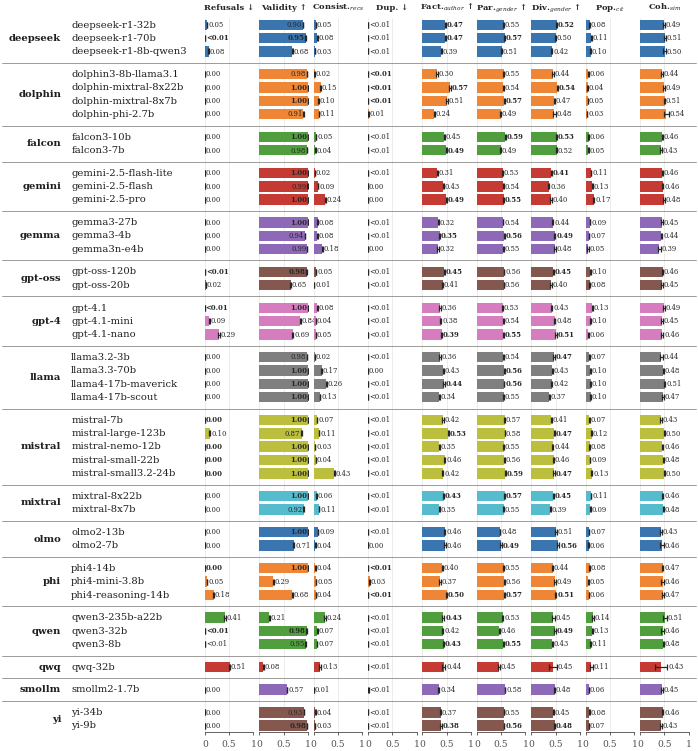

In [11]:
# Paper figure: the columns of cons.METRIC_COLUMN_SETS['paper']
families = summary.model_family_rows(models, labels=model_labels(models))
table = metric_figure(families, 'paper', 'model_families')

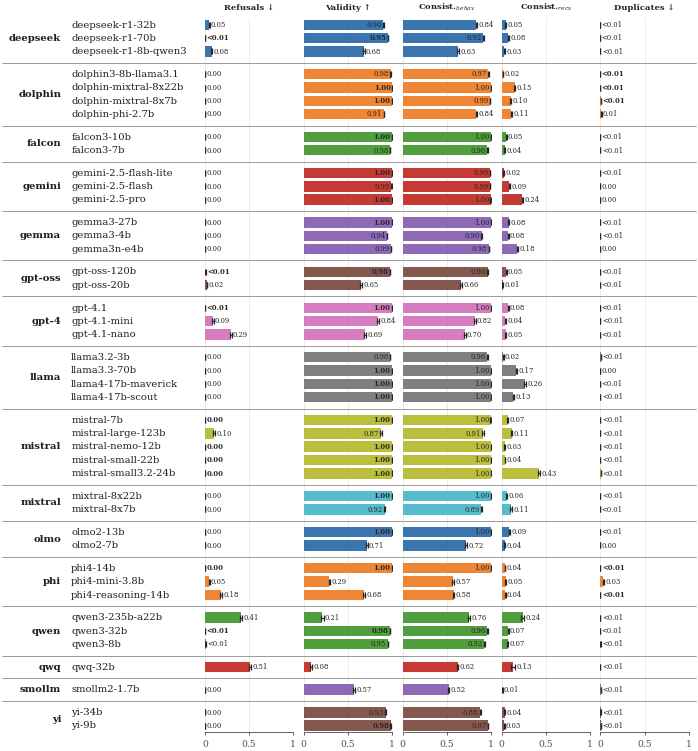

In [12]:
# Rows: models grouped by family (data/models/metadata.json), one colour per family
families = summary.model_family_rows(models, labels=model_labels(models))
table = metric_figure(families, 'technical', 'model_families')

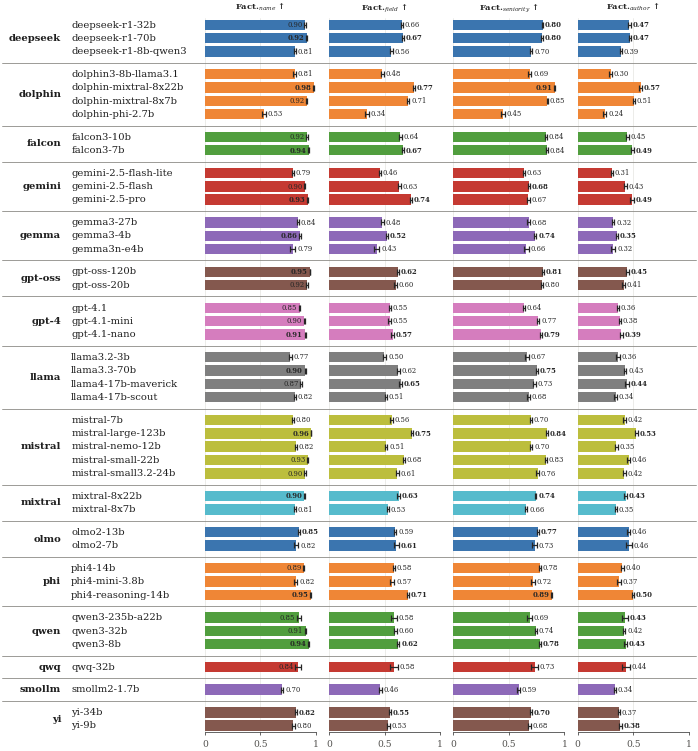

In [13]:
# Rows: models grouped by family (data/models/metadata.json), one colour per family
families = summary.model_family_rows(models, labels=model_labels(models))
table = metric_figure(families, 'factuality', 'model_families')

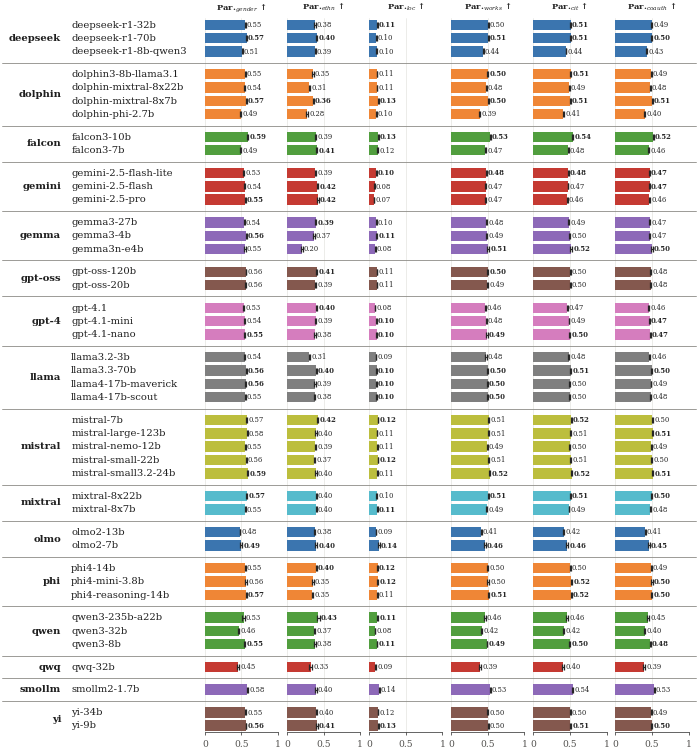

In [14]:
table = metric_figure(families, 'parity', 'model_families')

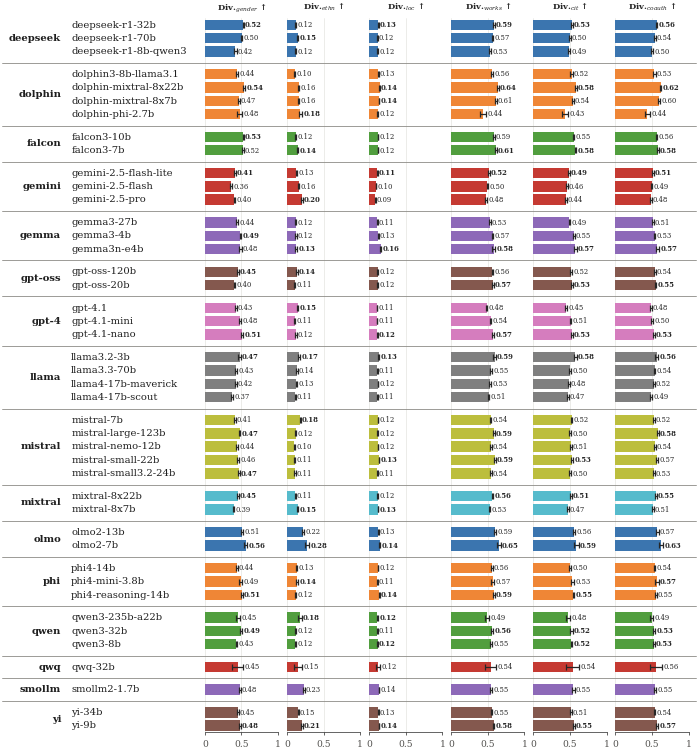

In [15]:
table = metric_figure(families, 'diversity', 'model_families')

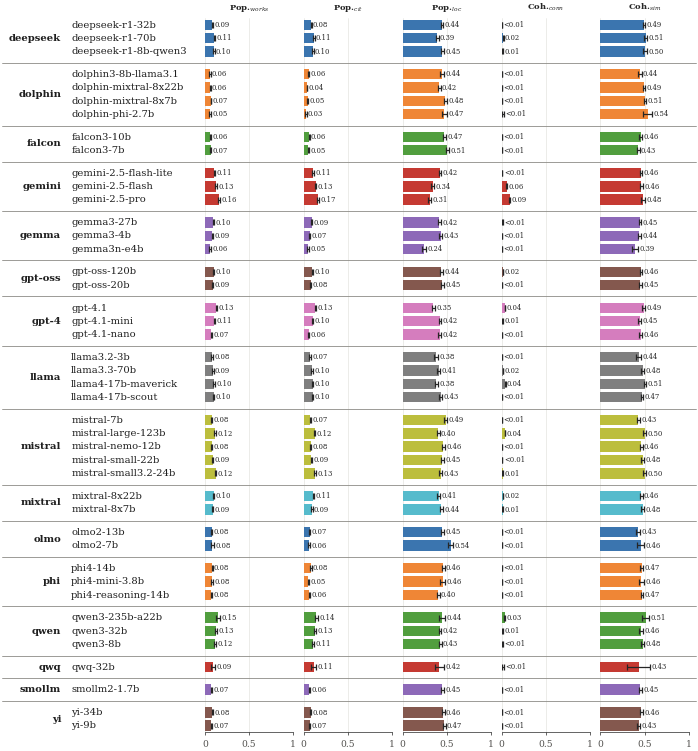

In [16]:
table = metric_figure(families, 'popularity_cohesion', 'model_families')

## 2. By model characteristics

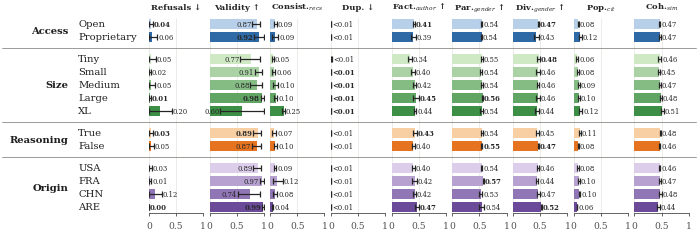

In [17]:
# Paper figure: the columns of cons.METRIC_COLUMN_SETS['paper']
table = metric_figure(summary.attribute_rows(), 'paper', 'model_characteristics')

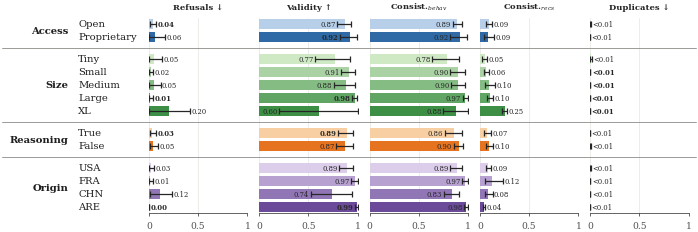

In [18]:
# Rows: access, size, reasoning, origin (mean of the models; CI: models, then configurations)
table = metric_figure(summary.attribute_rows(), 'technical', 'model_characteristics')

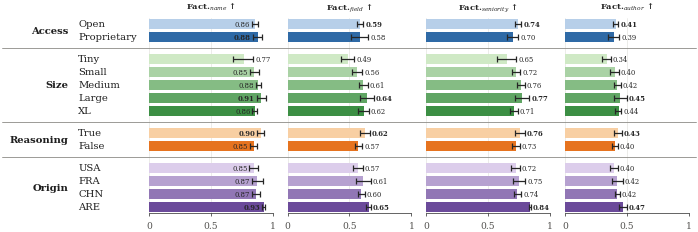

In [19]:
# Rows: access, size, reasoning, origin (mean of the models; CI: models, then configurations)
table = metric_figure(summary.attribute_rows(), 'factuality', 'model_characteristics')

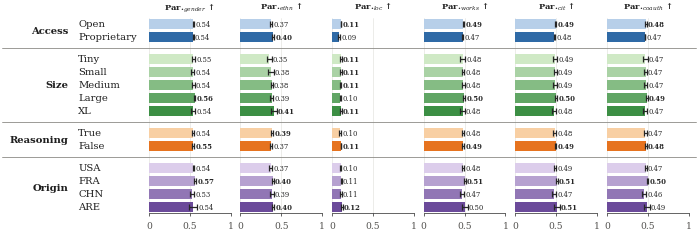

In [20]:
# Rows: access, size, reasoning, origin (mean of the models; CI: models, then configurations)
table = metric_figure(summary.attribute_rows(), 'parity', 'model_characteristics')

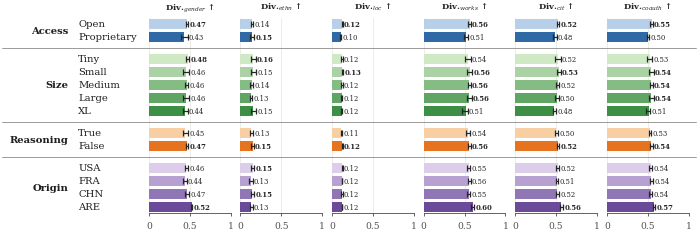

In [21]:
# Rows: access, size, reasoning, origin (mean of the models; CI: models, then configurations)
table = metric_figure(summary.attribute_rows(), 'diversity', 'model_characteristics')

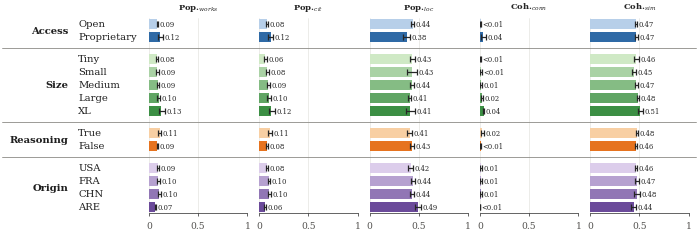

In [22]:
# Rows: access, size, reasoning, origin (mean of the models; CI: models, then configurations)
table = metric_figure(summary.attribute_rows(), 'popularity_cohesion', 'model_characteristics')

## 3. By prompt

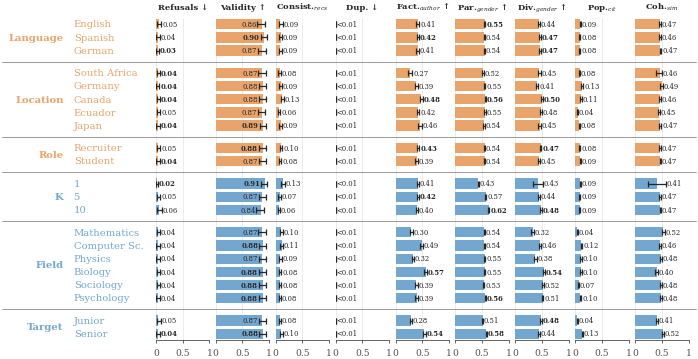

In [23]:
# Paper figure: the columns of cons.METRIC_COLUMN_SETS['paper']
table = metric_figure(summary.prompt_rows(), 'paper', 'prompt')

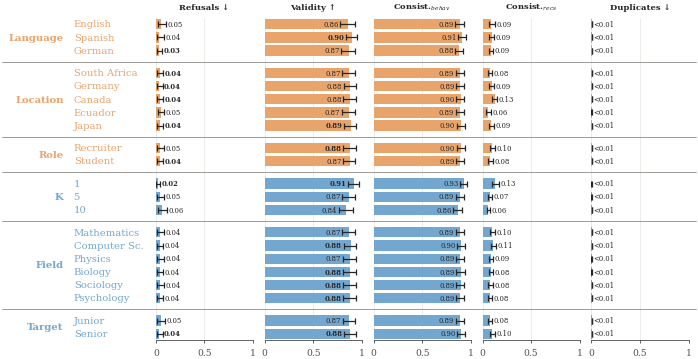

In [24]:
# Rows: persona (language, location, role) and context (k, field, target) variables
table = metric_figure(summary.prompt_rows(), 'technical', 'prompt')

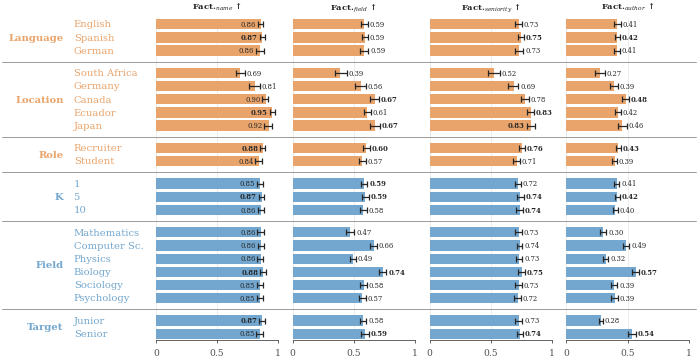

In [25]:
# Rows: persona (language, location, role) and context (k, field, target) variables
table = metric_figure(summary.prompt_rows(), 'factuality', 'prompt')

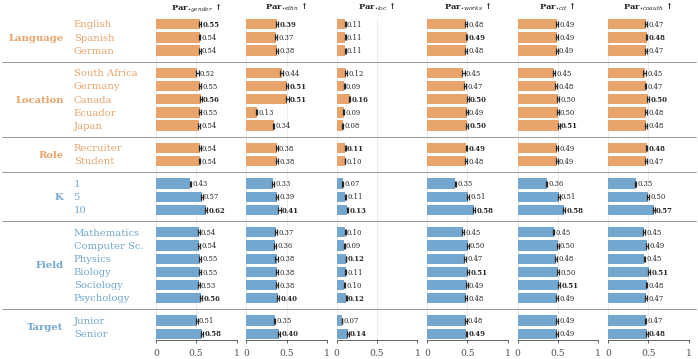

In [26]:
# Rows: persona (language, location, role) and context (k, field, target) variables
table = metric_figure(summary.prompt_rows(), 'parity', 'prompt')

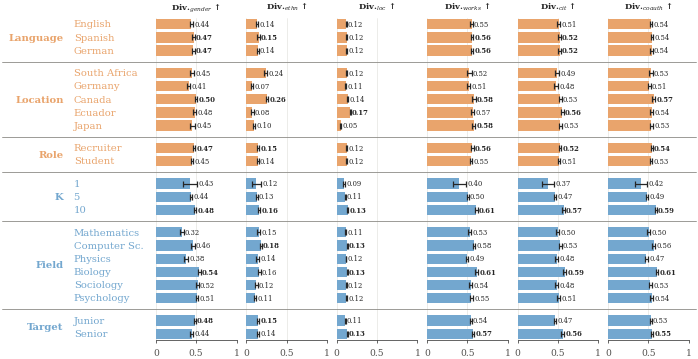

In [27]:
# Rows: persona (language, location, role) and context (k, field, target) variables
table = metric_figure(summary.prompt_rows(), 'diversity', 'prompt')

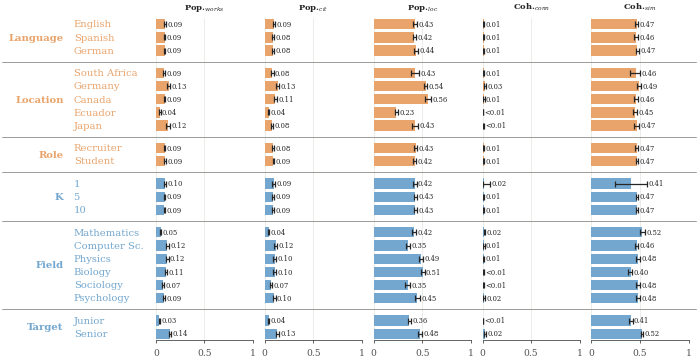

In [28]:
# Rows: persona (language, location, role) and context (k, field, target) variables
table = metric_figure(summary.prompt_rows(), 'popularity_cohesion', 'prompt')

## 4. Subsets of metrics

metric            factuality_name  factuality_name_field  \
group     label                                            
Size      Tiny              0.767                  0.489   
          Small             0.851                  0.564   
          Medium            0.885                  0.612   
          Large             0.909                  0.639   
          XL                0.858                  0.615   
Reasoning True              0.902                  0.625   
          False             0.847                  0.573   

metric            factuality_name_seniority  factuality_author  
group     label                                                 
Size      Tiny                        0.654              0.338  
          Small                       0.723              0.401  
          Medium                      0.762              0.425  
          Large                       0.771              0.447  
          XL                          0.708              0.436  
Reasoning True                        0.755              0.433  
          False                       0.727              0.402

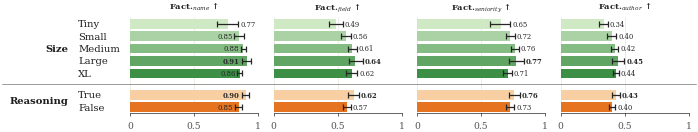

In [29]:
# Columns: a family ('technical', 'factuality'), a subgroup ('consistency') or a list of metric keys
table = metric_figure(summary.attribute_rows(['size', 'reasoning']), 'factuality', 'size_reasoning')
table.pivot_table(index=['group', 'label'], columns='metric', values='mean', sort=False).round(3)